# 02 — Utilidad multiobjetivo, precisión, tiempo e interpretabilidad

La pregunta principal es qué calidad multiobjetivo observada permiten alcanzar los regresores al seleccionar diseños de un catálogo común, y cómo se relaciona con su precisión, estabilidad y costo.

Se presentan resultados de validación y prueba. La selección de familia permanece congelada por validación; describir otra familia con mejor promedio en prueba no cambia esa decisión. Todas las tablas, cifras de interpretación y figuras se calculan a partir de los artefactos existentes, sin entrenar ni volver a predecir.

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = {"png", "svg"}
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from truss_research.evaluacion.presentacion import notebook_context

context = notebook_context()
CONFIG = context.config
STUDY_DIR, REPORT_DIR = context.study_dir, context.report_dir
DATA_DIR = CONFIG.data_dir
display(
    Markdown(
        f"**Estudio:** `{STUDY_DIR.name}` — **etiqueta:** `{CONFIG.label}` — **informe:** `{REPORT_DIR.name}`"
    )
)
if CONFIG.label == "comprobacion":
    display(
        Markdown(
            "**Comprobación técnica: sus métricas no constituyen resultados de tesis.**"
        )
    )

**Estudio:** `comparacion_tres_objetivos_final_002` — **etiqueta:** `posterior` — **informe:** `informe_001`

## 1. Configuración y familia congelada

Las familias y presupuestos se leen del estudio. Los transformadores se ajustan con entrenamiento; las OOF progresivas excluyen generaciones futuras de selección y ajuste y dejan calentamiento sin predicciones. TabPFN usa pesos preentrenados sin Optuna ni fine-tuning; Targetwise selecciona componentes por respuesta.

La familia principal se eligió por mayor AUC observado de validación en el menor presupuesto configurado, con MAE normalizado como desempate. El MAE sigue siendo el criterio del ajuste interno. La elección se lee del cierre; no se recalcula usando prueba.

familias                                                 (dummy, ridge, random_forest, svr, gpr, catboo...
semillas                                                                              (42, 43, 44, 45, 46)
presupuestos                                                                                  (32, 64, 96)
intentos_por_búsqueda                                                                                   30
pliegues_externos                                                                                        5
pliegues_internos                                                                                        3
selección_congelada_evaluador_representante_asistente                      [xgboost, random_forest, ridge]
dtype: object

,split,model,role,budget,mean_auc,mean_hypervolume,mean_normalized_auc,effective_budget,catalogue_size
0,validation,catboost,regressor,32,0.064709,0.081835,0.716293,32,96
1,validation,catboost,regressor,64,0.074075,0.084204,0.819961,64,96
2,validation,catboost,regressor,96,0.077500,0.084397,0.857871,96,96
3,validation,dummy,regressor,32,0.062671,0.077687,0.693732,32,96
4,validation,dummy,regressor,64,0.071474,0.082316,0.791168,64,96
5,validation,dummy,regressor,96,0.075444,0.084115,0.835116,96,96
6,validation,gpr,regressor,32,0.064661,0.081629,0.715752,32,96
7,validation,gpr,regressor,64,0.073900,0.083773,0.818029,64,96
8,validation,gpr,regressor,96,0.077345,0.084397,0.856164,96,96
9,validation,lightgbm,regressor,32,0.064210,0.081354,0.710770,32,96


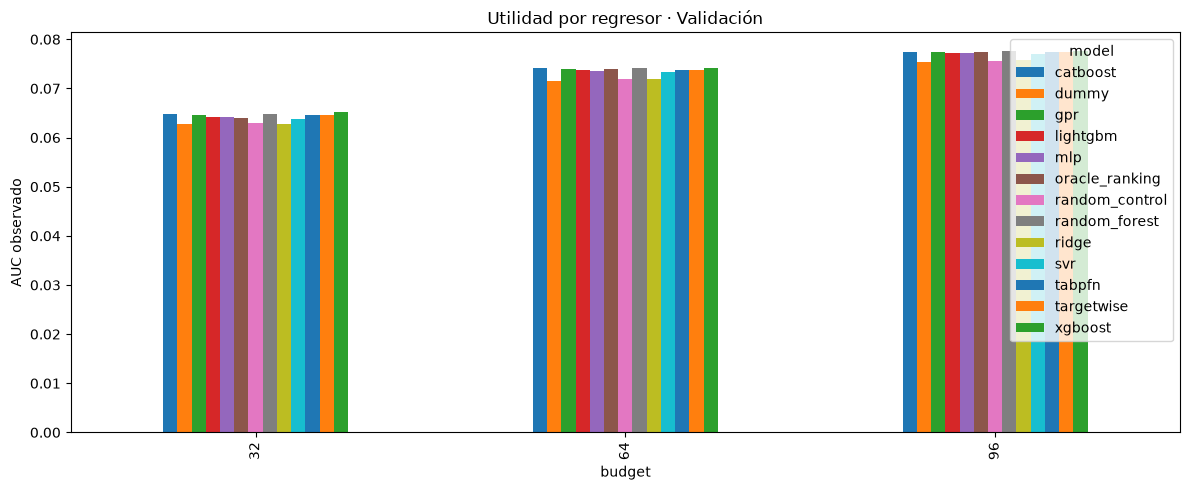

,split,model,role,budget,mean_auc,mean_hypervolume,mean_normalized_auc,effective_budget,catalogue_size
39,test,catboost,regressor,32,0.066116,0.081809,0.731865,32,96
40,test,catboost,regressor,64,0.074838,0.084276,0.828409,64,96
41,test,catboost,regressor,96,0.078105,0.084746,0.864575,96,96
42,test,dummy,regressor,32,0.064405,0.078224,0.712922,32,96
43,test,dummy,regressor,64,0.072430,0.082242,0.801755,64,96
44,test,dummy,regressor,96,0.076104,0.084423,0.842425,96,96
45,test,gpr,regressor,32,0.066999,0.082461,0.741635,32,96
46,test,gpr,regressor,64,0.075264,0.084270,0.833124,64,96
47,test,gpr,regressor,96,0.078371,0.084746,0.867513,96,96
48,test,lightgbm,regressor,32,0.067369,0.082385,0.745734,32,96


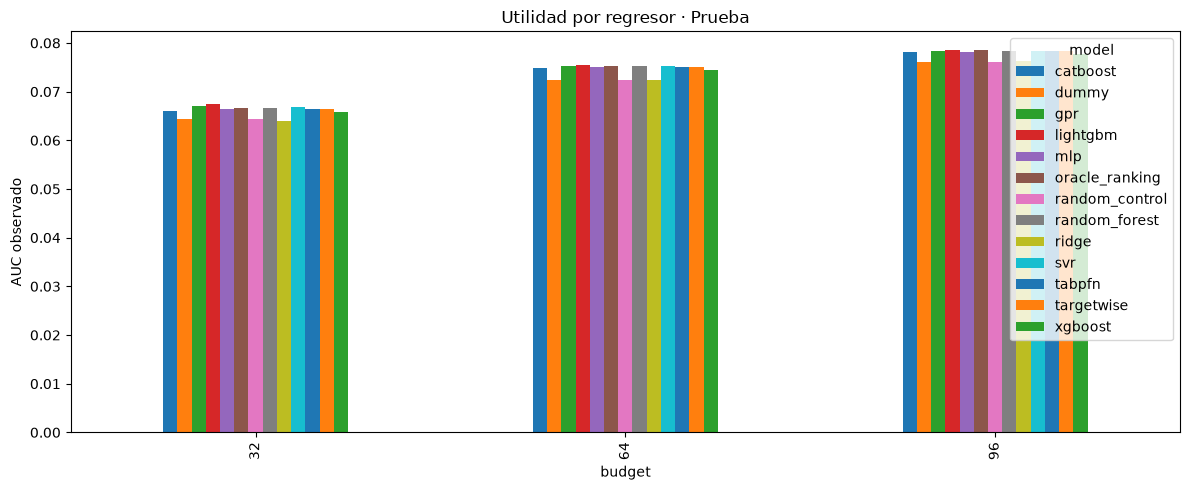

In [2]:
display(
    pd.Series(
        {
            "familias": CONFIG.models,
            "semillas": CONFIG.seeds,
            "presupuestos": CONFIG.budgets,
            "intentos_por_búsqueda": CONFIG.trials,
            "pliegues_externos": CONFIG.outer_folds,
            "pliegues_internos": CONFIG.inner_folds,
            "selección_congelada_evaluador_representante_asistente": context.frozen[
                "selected"
            ],
        }
    )
)
utility = pd.read_csv(REPORT_DIR / "predictor_utility_summary.csv")
for split, label in (("validation", "Validación"), ("test", "Prueba")):
    table = utility.loc[utility["split"].eq(split)]
    display(table)
    table.pivot(index="budget", columns="model", values="mean_auc").plot.bar(
        figsize=(12, 5),
        ylabel="AUC observado",
        title=f"Utilidad por regresor · {label}",
    )
    plt.tight_layout()
    plt.show()

## 2. Comparaciones pareadas de utilidad

Todos los regresores comparten catálogos, inicialización y presupuesto. La calidad se calcula con respuestas observadas, aunque la decisión use predicciones. Los presupuestos efectivos se reducen al agotarse un catálogo. El oráculo usa etiquetas con el mismo ranking: no es un óptimo global ni una cota de AUC.

Los intervalos promedian semillas antes de remuestrear escenarios pareados. Son exploratorios y puntuales; catálogos superpuestos y semillas no constituyen nuevos problemas estructurales independientes.

In [3]:
display(pd.read_csv(REPORT_DIR / "predictor_utility_paired_intervals.csv"))
display(pd.read_csv(REPORT_DIR / "prediction_utility.csv"))

,budget,model,reference_model,mean_auc_difference,ci_lower,ci_upper,scenario_pairs,scope,split
0,32,catboost,dummy,0.002038,0.001143,0.002933,20,pointwise_exploratory_fixed_fits_seed_averaged...,validation
1,32,catboost,gpr,0.000049,-0.000171,0.000273,20,pointwise_exploratory_fixed_fits_seed_averaged...,validation
2,32,catboost,lightgbm,0.000499,0.000259,0.000740,20,pointwise_exploratory_fixed_fits_seed_averaged...,validation
3,32,catboost,mlp,0.000498,0.000380,0.000604,20,pointwise_exploratory_fixed_fits_seed_averaged...,validation
4,32,catboost,oracle_ranking,0.000703,0.000512,0.000903,20,pointwise_exploratory_fixed_fits_seed_averaged...,validation
...,...,...,...,...,...,...,...,...,...
463,96,svr,targetwise,0.000115,0.000048,0.000196,20,pointwise_exploratory_fixed_fits_seed_averaged...,test
464,96,svr,xgboost,0.000677,0.000552,0.000810,20,pointwise_exploratory_fixed_fits_seed_averaged...,test
465,96,tabpfn,targetwise,0.000000,0.000000,0.000000,20,pointwise_exploratory_fixed_fits_seed_averaged...,test
466,96,tabpfn,xgboost,0.000561,0.000438,0.000695,20,pointwise_exploratory_fixed_fits_seed_averaged...,test


,split,model,role,budget,mean_auc,mean_hypervolume,mean_normalized_auc,effective_budget,catalogue_size,normalized_mae
0,validation,catboost,regressor,32,0.064709,0.081835,0.716293,32,96,0.057491
1,validation,catboost,regressor,64,0.074075,0.084204,0.819961,64,96,0.057491
2,validation,catboost,regressor,96,0.077500,0.084397,0.857871,96,96,0.057491
3,validation,dummy,regressor,32,0.062671,0.077687,0.693732,32,96,0.786876
4,validation,dummy,regressor,64,0.071474,0.082316,0.791168,64,96,0.786876
...,...,...,...,...,...,...,...,...,...,...
73,test,targetwise,regressor,64,0.075148,0.084585,0.831845,64,96,0.050223
74,test,targetwise,regressor,96,0.078324,0.084746,0.866997,96,96,0.050223
75,test,xgboost,regressor,32,0.065913,0.081517,0.729615,32,96,0.075903
76,test,xgboost,regressor,64,0.074521,0.083808,0.824903,64,96,0.075903


## 3. Errores en sus unidades y variación entre semillas

El MAE normalizado divide por desviaciones de entrenamiento y promedia las tres respuestas con pesos iguales; no es un porcentaje. MAE, RMSE, sesgo y percentil 95 describen errores físicos. Las semillas comparten fuente y partición; algunas familias deterministas pueden producir predicciones idénticas.

In [4]:
from truss_research.evaluacion.lectura_resultados import predictor_interpretation

display(pd.read_csv(REPORT_DIR / "predictive_model_summary.csv"))
display(pd.read_csv(REPORT_DIR / "predictive_seed_metrics.csv"))
display(pd.read_csv(REPORT_DIR / "predictive_category_metrics.csv"))


display(
    Markdown(
        predictor_interpretation(
            REPORT_DIR, context.frozen["selected"][0], min(CONFIG.budgets)
        )
    )
)

,split,model,mean,std,min,max,adjustment_seeds
0,test,catboost,0.065732,0.001112,0.064079,0.067179,5
1,test,dummy,0.780447,0.000000,0.780447,0.780447,5
2,test,gpr,0.079224,0.000000,0.079224,0.079224,5
3,test,lightgbm,0.076244,0.000000,0.076244,0.076244,5
4,test,mlp,0.074468,0.007250,0.067611,0.085514,5
5,test,random_forest,0.080116,0.000528,0.079228,0.080591,5
6,test,ridge,0.236341,0.000000,0.236341,0.236341,5
7,test,svr,0.074392,0.000000,0.074392,0.074392,5
8,test,tabpfn,0.050223,0.000573,0.049247,0.050742,5
9,test,targetwise,0.050223,0.000573,0.049247,0.050742,5


,target,mae,rmse,r2,bias,p95_absolute_error,count,normalized_mae,split,model,seed
0,mass_kg,507.353826,957.939509,0.951446,-90.781416,1443.473128,108,0.108553,test,catboost,42
1,util_ratio,0.011967,0.016991,0.991578,-0.000805,0.036111,108,0.061383,test,catboost,42
2,z_disp_m,0.000557,0.000842,0.994326,-0.000160,0.002023,108,0.027717,test,catboost,42
3,mass_kg,487.745403,900.245441,0.957118,-44.336383,1229.589144,108,0.104358,test,catboost,43
4,util_ratio,0.012244,0.016852,0.991715,-0.000161,0.033519,108,0.062806,test,catboost,43
...,...,...,...,...,...,...,...,...,...,...,...
325,util_ratio,0.017697,0.027350,0.979207,0.002111,0.062196,98,0.090777,validation,xgboost,45
326,z_disp_m,0.000759,0.001063,0.993944,0.000172,0.002161,98,0.037761,validation,xgboost,45
327,mass_kg,374.632552,513.572860,0.987161,19.622409,1050.157698,98,0.080156,validation,xgboost,46
328,util_ratio,0.017697,0.027350,0.979207,0.002111,0.062196,98,0.090777,validation,xgboost,46


,target,mae,rmse,r2,bias,p95_absolute_error,count,web_config,split,model,seed
0,mass_kg,4234.738548,4272.059482,-56.485189,4234.738548,4741.848131,2,0,validation,dummy,42
1,util_ratio,0.306961,0.308167,-127.041083,-0.306961,0.331472,2,0,validation,dummy,42
2,z_disp_m,0.014356,0.014453,-73.761658,-0.014356,0.015860,2,0,validation,dummy,42
3,mass_kg,3824.856335,4187.009280,-0.241446,1846.503198,5992.333253,39,1,validation,dummy,42
4,util_ratio,0.167911,0.189862,-0.008336,-0.017263,0.330294,39,1,validation,dummy,42
...,...,...,...,...,...,...,...,...,...,...,...
820,util_ratio,0.010150,0.014818,0.994939,-0.001988,0.034109,50,1,test,tabpfn,46
821,z_disp_m,0.000498,0.000843,0.994421,0.000063,0.001407,50,1,test,tabpfn,46
822,mass_kg,348.776590,502.458673,0.984141,-43.833453,1232.626790,58,2,test,tabpfn,46
823,util_ratio,0.007140,0.009695,0.994851,0.001453,0.018790,58,2,test,tabpfn,46


Con presupuesto **32**, la mayor media descriptiva de AUC normalizado en prueba corresponde a **lightgbm (0.7457)**. La familia elegida en validación, **xgboost**, alcanza **0.7296** y conserva su rol congelado: el orden de prueba no se usa para cambiarla. El menor MAE normalizado medio corresponde a **tabpfn, targetwise (0.0502)**. Estos criterios responden preguntas distintas: reconstruir respuestas con menor error no garantiza seleccionar mejores alternativas multiobjetivo. Las posiciones son descriptivas; los contrastes pareados delimitan la incertidumbre y no establecen superioridad poblacional.

## 4. Intervalos de error y cobertura

`generation_block` remuestrea bloques de generaciones tras promediar pérdidas entre semillas; `design_iid_sensitivity` es un control por diseño. Pocos bloques limitan la estabilidad. No se declara significación, equivalencia ni seguridad.

Los intervalos predictivos usan calibración separada del ajuste. La deriva temporal y las categorías ausentes limitan su interpretación; cobertura marginal no garantiza cobertura conjunta ni durante selección adaptativa.

In [5]:
display(pd.read_csv(REPORT_DIR / "predictive_paired_errors.csv"))
display(pd.read_csv(REPORT_DIR / "category_coverage.csv"))
interval_path = REPORT_DIR / "predictive_interval_coverage.csv"
if interval_path.is_file():
    display(pd.read_csv(interval_path))
else:
    display(Markdown("Este informe no contiene intervalos predictivos exportados."))

,model,reference_model,target,contrast,resampling,count,blocks,block_generations,mean_difference,ci_lower,ci_upper,bootstrap_repeats,interval_status,scope,split
0,catboost,dummy,mass_kg,primary_control,generation_block,108,5,2.0,-3312.104668,-3788.279140,-2880.435068,2000,exploratory_few_blocks,pointwise_conditional_single_trajectory_no_mul...,test
1,catboost,gpr,mass_kg,secondary_family,generation_block,108,5,2.0,-202.000246,-252.700539,-162.483935,2000,exploratory_few_blocks,pointwise_conditional_single_trajectory_no_mul...,test
2,catboost,lightgbm,mass_kg,secondary_family,generation_block,108,5,2.0,-57.329905,-133.694127,-1.047336,2000,exploratory_few_blocks,pointwise_conditional_single_trajectory_no_mul...,test
3,catboost,mlp,mass_kg,secondary_family,generation_block,108,5,2.0,-67.784281,-150.689995,-19.889658,2000,exploratory_few_blocks,pointwise_conditional_single_trajectory_no_mul...,test
4,catboost,random_forest,mass_kg,secondary_family,generation_block,108,5,2.0,-78.652227,-124.245529,-37.097218,2000,exploratory_few_blocks,pointwise_conditional_single_trajectory_no_mul...,test
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
875,svr,targetwise,normalized_mae,secondary_family,design_iid_sensitivity,98,98,NaN,0.028282,0.020587,0.036283,2000,exploratory,pointwise_conditional_single_trajectory_no_mul...,validation
876,svr,xgboost,normalized_mae,secondary_family,design_iid_sensitivity,98,98,NaN,0.001176,-0.008202,0.010505,2000,exploratory,pointwise_conditional_single_trajectory_no_mul...,validation
877,tabpfn,targetwise,normalized_mae,secondary_family,design_iid_sensitivity,98,98,NaN,0.000000,0.000000,0.000000,2000,exploratory,pointwise_conditional_single_trajectory_no_mul...,validation
878,tabpfn,xgboost,normalized_mae,secondary_family,design_iid_sensitivity,98,98,NaN,-0.027106,-0.034506,-0.019754,2000,exploratory,pointwise_conditional_single_trajectory_no_mul...,validation


,web_config,unique_designs,split,scarce_evidence,scarcity_threshold,interpretation
0,0,10,train,False,10,descriptive_threshold_not_statistical_power
1,1,393,train,False,10,descriptive_threshold_not_statistical_power
2,2,441,train,False,10,descriptive_threshold_not_statistical_power
3,3,46,train,False,10,descriptive_threshold_not_statistical_power
4,4,11,train,False,10,descriptive_threshold_not_statistical_power
5,0,2,validation,True,10,descriptive_threshold_not_statistical_power
6,1,39,validation,False,10,descriptive_threshold_not_statistical_power
7,2,57,validation,False,10,descriptive_threshold_not_statistical_power
8,3,0,validation,True,10,descriptive_threshold_not_statistical_power
9,4,0,validation,True,10,descriptive_threshold_not_statistical_power


,split,model,seed,target,nominal_coverage,web_config,observed_coverage,mean_width,count
0,test,catboost,42,mass_kg,0.90,1,0.800000,1743.828626,50
1,test,catboost,42,mass_kg,0.90,2,0.913793,1743.828626,58
2,test,catboost,42,mass_kg,0.95,1,0.920000,2982.328938,50
3,test,catboost,42,mass_kg,0.95,2,0.965517,2982.328938,58
4,test,catboost,42,util_ratio,0.90,1,0.840000,0.068418,50
...,...,...,...,...,...,...,...,...,...
1645,validation,xgboost,46,z_disp_m,0.90,1,0.948718,0.003832,39
1646,validation,xgboost,46,z_disp_m,0.90,2,0.894737,0.003832,57
1647,validation,xgboost,46,z_disp_m,0.95,0,1.000000,0.005713,2
1648,validation,xgboost,46,z_disp_m,0.95,1,0.974359,0.005713,39


## 5. Comparación de tiempos: ajuste e inferencia

Se separan tres fases de trabajo: búsqueda final de hiperparámetros, OOF anidadas y ajustes finales. El gráfico apila únicamente esas fases registradas, sumadas entre las semillas y preparaciones compartidas. No representa duración de reloj de campaña; el paralelismo y la verificación de artefactos tienen otros registros. La selección interna ya contenida en OOF no se suma otra vez.

La inferencia usa mediciones sobre prueba: se muestra la media entre semillas de las medianas por consulta individual y por lote. El tiempo por diseño dentro del lote se obtiene de cada medición antes de promediar. No equivale a la latencia de una consulta individual. La tabla informa el tamaño de lote y el dispositivo efectivo; el gráfico usa escala logarítmica para comparar órdenes de magnitud.

TabPFN incorpora preentrenamiento externo cuyo costo no fue medido. Targetwise incluye selección de componentes, aunque sus predicciones finales puedan coincidir con otra familia. Un ajuste local más corto no implica menor costo total de desarrollo ni una comparación igualada de hardware.

,model,seed,normalized_mae,cv_normalized_mae,tuning_seconds,crossfit_seconds,fit_seconds,reuse_seconds,device,requested_trials,trial_count,nested_trial_count,targetwise_family_trials,search_reused
0,dummy,42,0.786876,0.785196,0.000955,0.701126,0.006398,0.000000,cpu,30,0,0,0,False
1,dummy,43,0.786876,0.785196,0.000000,0.000000,0.010375,0.014907,cpu,30,0,0,0,True
2,dummy,44,0.786876,0.785196,0.000000,0.000000,0.006590,0.037336,cpu,30,0,0,0,True
3,dummy,45,0.786876,0.785196,0.000000,0.000000,0.008531,0.018040,cpu,30,0,0,0,True
4,dummy,46,0.786876,0.785196,0.000000,0.000000,0.008458,0.015342,cpu,30,0,0,0,True
5,ridge,42,0.242709,0.251220,13.638864,65.523292,0.036498,0.000000,cpu,30,30,150,0,False
6,ridge,43,0.242709,0.251220,0.000000,0.000000,0.024757,0.019432,cpu,30,0,0,0,True
7,ridge,44,0.242709,0.251220,0.000000,0.000000,0.016990,0.014771,cpu,30,0,0,0,True
8,ridge,45,0.242709,0.251220,0.000000,0.000000,0.013391,0.018838,cpu,30,0,0,0,True
9,ridge,46,0.242709,0.251220,0.000000,0.000000,0.023141,0.026604,cpu,30,0,0,0,True


,Búsqueda final (s),OOF anidadas (s),Ajustes finales (s),Suma de fases (min),Semillas,Dispositivo,Consulta individual (ms),Lote completo (ms),Por diseño en lote (ms),Diseños por lote
model,,,,,,,,,,
catboost,1100.756,5208.190,59.482,106.140,5,cpu,2.597,2.920,0.027,108.0
dummy,0.001,0.701,0.040,0.012,5,cpu,1.323,1.296,0.012,108.0
gpr,255.539,581.905,52.818,14.838,5,cpu,2.317,5.392,0.050,108.0
lightgbm,31.896,156.576,0.843,3.155,5,cpu,3.374,5.710,0.053,108.0
mlp,168.227,528.148,15.571,11.866,5,cpu,1.859,1.890,0.018,108.0
random_forest,97.703,599.218,5.211,11.702,5,cpu,14.522,17.114,0.158,108.0
ridge,13.639,65.523,0.115,1.321,5,cpu,2.029,2.047,0.019,108.0
svr,40.252,131.927,4.170,2.939,5,cpu,2.621,15.954,0.148,108.0
tabpfn,0.001,30.075,10.154,0.671,5,cuda,407.797,431.532,3.996,108.0


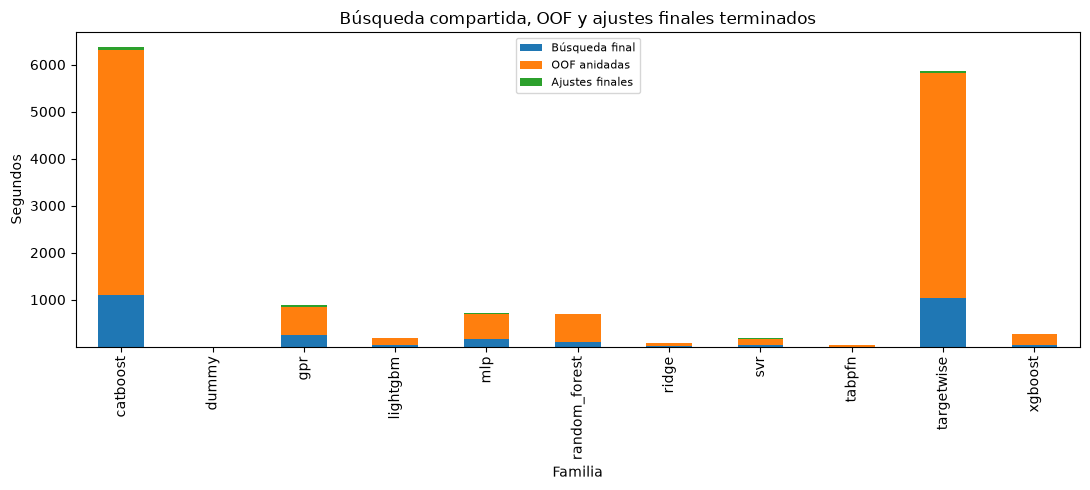

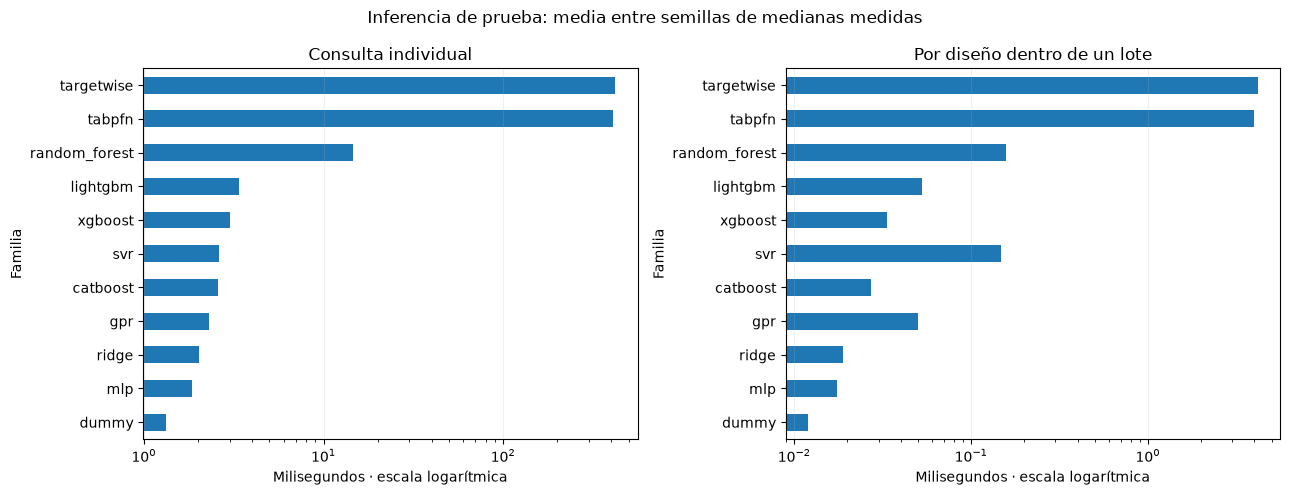

Las fases registradas de ajuste de **xgboost** suman **4.48 min**. La mayor suma corresponde a **catboost (106.14 min)**. La inferencia individual de **xgboost** registra una media entre semillas de medianas de **3.000 ms**. Las familias con menor MAE normalizado, **tabpfn, targetwise**, registran **413.690 ms** como promedio de esas latencias. La tabla y el gráfico permiten valorar si la precisión adicional compensa la latencia para el uso previsto. La suma de fases de ajuste corresponde al trabajo registrado de todas las semillas y preparaciones compartidas; no es el tiempo transcurrido de campaña ni incluye el preentrenamiento externo de TabPFN. Las fases OOF incluyen su selección interna y no deben sumarse de nuevo a los totales de recursos. CPU y CUDA se indican porque sus tiempos no constituyen una comparación a hardware idéntico.

In [6]:
from truss_research.evaluacion.figuras import (
    predictor_cost_figure,
    predictor_inference_figure,
)
from truss_research.evaluacion.lectura_resultados import (
    time_comparison,
    time_interpretation,
)

display(pd.read_csv(REPORT_DIR / "predictor_costs.csv"))
times = time_comparison(REPORT_DIR)
display(
    times.rename(
        columns={
            "tuning_seconds": "Búsqueda final (s)",
            "crossfit_seconds": "OOF anidadas (s)",
            "fit_seconds": "Ajustes finales (s)",
            "fit_phase_minutes": "Suma de fases (min)",
            "adjustment_seeds": "Semillas",
            "device": "Dispositivo",
            "individual_ms": "Consulta individual (ms)",
            "batch_ms": "Lote completo (ms)",
            "batch_per_design_ms": "Por diseño en lote (ms)",
            "batch_rows": "Diseños por lote",
        }
    ).round(3)
)
for figure in (
    predictor_cost_figure(REPORT_DIR),
    predictor_inference_figure(REPORT_DIR),
):
    display(figure)
    plt.close(figure)
display(Markdown(time_interpretation(REPORT_DIR, context.frozen["selected"][0])))

## 6. SHAP completo: coincidencias entre familias y limites

SHAP explica las predicciones en los mismos casos de validación, usando referencia de entrenamiento. Las familias se explican en su semilla representativa; las semillas adicionales de la familia congelada son configurables. El piloto permanece separado. La figura del evaluador congelado muestra magnitudes en unidades físicas; el mapa entre familias normaliza por respuesta para comparar el reparto de importancia, no su precisión.

Dummy tiene contribuciones nulas, Ridge usa explicación lineal y los árboles usan TreeExplainer con comprobación de reconstrucción y alternativa por permutaciones. Targetwise se explica por componente. Los métodos declaran supuestos distintos: no se interpretan sus magnitudes como evidencia causal ni como clasificación de calidad.

Para TabPFN, incluidas las componentes Targetwise, máscaras y reconstrucción usan inferencia en lotes de tamaño fijo, completados con repeticiones que después se descartan. Esta política evita inconsistencias por tamaño de lote y no cambia los modelos ni los resultados científicos de la campaña. La tolerancia de aditividad se conserva. Los contadores de filas solicitadas excluyen el relleno y el costo se informa por separado.

Una variable puede dominar las atribuciones por la distribución y las dependencias presentes en esta fuente. Compartir esa prioridad entre modelos no demuestra que intervenir físicamente sobre ella produzca el mismo efecto ni permite eliminar otras variables.

,model,seed,target,variable,abs_shap
0,catboost,42,mass_kg,lmrm_height_m,103.690294
1,catboost,42,mass_kg,lr_height_m,171.115977
2,catboost,42,mass_kg,m_height_m,94.399436
3,catboost,42,mass_kg,n_trusses,3490.662997
4,catboost,42,mass_kg,subdiv1,450.509840
...,...,...,...,...,...
226,xgboost,42,z_disp_m,m_height_m,0.005883
227,xgboost,42,z_disp_m,n_trusses,0.008951
228,xgboost,42,z_disp_m,subdiv1,0.000090
229,xgboost,42,z_disp_m,subdiv2,0.000729


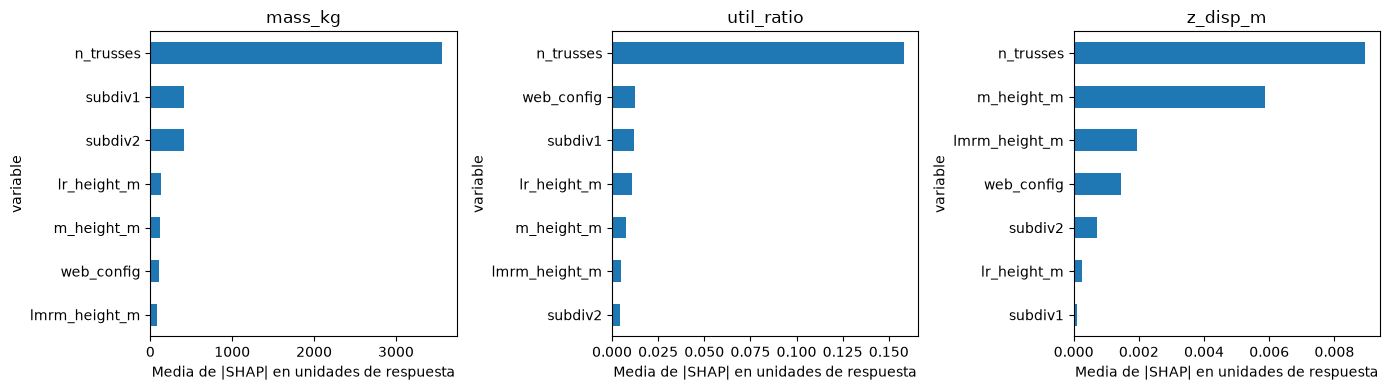

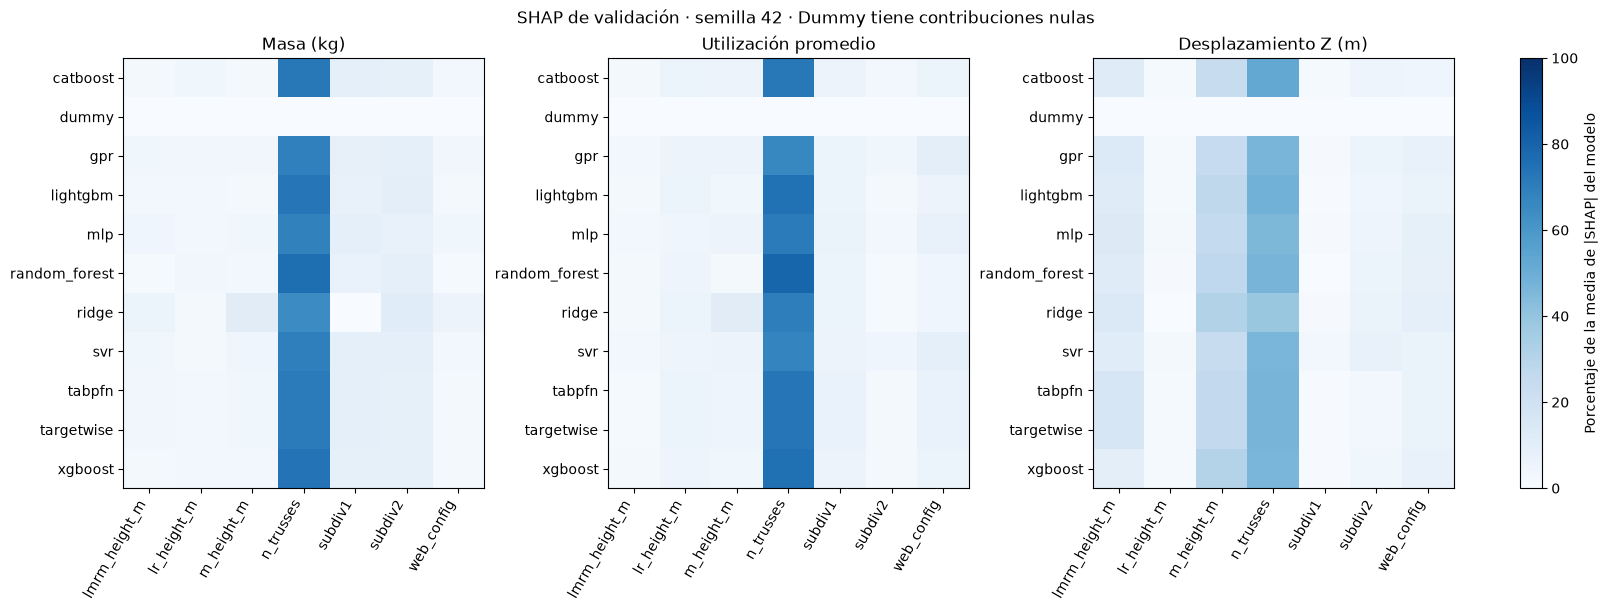

En la semilla representativa **42**, excluyendo el modelo constante:
- **mass_kg**: `n_trusses` ocupa el primer puesto en **10/10** familias, con **64.7–75.9%** de su importancia absoluta total.
- **util_ratio**: `n_trusses` ocupa el primer puesto en **10/10** familias, con **66.7–79.6%** de su importancia absoluta total.
- **z_disp_m**: `n_trusses` ocupa el primer puesto en **10/10** familias, con **38.6–52.6%** de su importancia absoluta total.

La concordancia describe modelos sobre una misma fuente, no réplicas independientes ni causalidad física. Los porcentajes normalizan la media de |SHAP| dentro de cada modelo y respuesta; no representan varianza explicada. Las familias con componentes idénticos pueden compartir atribuciones. Sin varias semillas explicadas no se estima estabilidad SHAP entre ajustes.

,iter_id,variable,target,shap_value,base_value,feature_value,model,seed
0,{80;14},web_config,mass_kg,0.000000,10270.341662,1.0,dummy,42
1,{80;14},web_config,util_ratio,0.000000,0.536316,1.0,dummy,42
2,{80;14},web_config,z_disp_m,0.000000,0.026742,1.0,dummy,42
3,{80;14},n_trusses,mass_kg,0.000000,10270.341662,15.0,dummy,42
4,{80;14},n_trusses,util_ratio,0.000000,0.536316,15.0,dummy,42
...,...,...,...,...,...,...,...,...
688,{80;19},subdiv1,util_ratio,-0.003193,0.537116,2.0,tabpfn,42
689,{80;19},subdiv1,z_disp_m,-0.000065,0.028163,2.0,tabpfn,42
690,{80;19},subdiv2,mass_kg,-185.221617,9662.349207,1.0,tabpfn,42
691,{80;19},subdiv2,util_ratio,-0.011551,0.537116,1.0,tabpfn,42


,model,seed,method,requested_method,fallback_reason,execution_device,explanation_seconds,counted_prediction_calls,counted_prediction_rows,permutation_completed_seconds,...,scope,component_methods,background_semantics,attempts,attempt_wall_seconds,attempt_cpu_seconds,peak_rss_mib,peak_gpu_allocated_mib,estimated_full_permutation_seconds,estimate_scope
0,dummy,42,constant,constant,NaN,cpu,0.280921,1,98,0.000000,...,full,[],Independent/linear/interventional usan la refe...,1,0.342841,0.265625,745.335938,NaN,0.000000,rough_permutation_scaling_only_excludes_load_t...
1,ridge,42,linear_independent,linear_independent,NaN,cpu,1.188797,1,98,0.000000,...,full,[],Independent/linear/interventional usan la refe...,1,1.212025,0.890625,775.480469,NaN,0.000000,rough_permutation_scaling_only_excludes_load_t...
2,random_forest,42,permutation_after_tree_additivity_failure,tree_interventional,tree_additivity_failure,cpu,39.344622,981,1144998,36.462621,...,full,[],Independent/linear/interventional usan la refe...,1,39.376927,38.937500,812.179688,NaN,36.462621,rough_permutation_scaling_only_excludes_load_t...
3,svr,42,permutation,permutation,NaN,cpu,128.950755,981,1144998,128.291885,...,full,[],Independent/linear/interventional usan la refe...,1,128.980136,138.343750,787.800781,NaN,128.291885,rough_permutation_scaling_only_excludes_load_t...
4,gpr,42,permutation,permutation,NaN,cpu,98.278121,981,1144998,97.553876,...,full,[],Independent/linear/interventional usan la refe...,1,98.303317,100.046875,863.523438,NaN,97.553876,rough_permutation_scaling_only_excludes_load_t...
5,catboost,42,tree_path_dependent,tree_path_dependent,NaN,cpu,0.715363,1,98,0.000000,...,full,[],Independent/linear/interventional usan la refe...,1,0.740315,1.187500,812.550781,NaN,0.000000,rough_permutation_scaling_only_excludes_load_t...
6,xgboost,42,tree_path_dependent,tree_path_dependent,NaN,cpu,0.416684,1,98,0.000000,...,full,[],Independent/linear/interventional usan la refe...,1,0.441058,0.390625,899.800781,NaN,0.000000,rough_permutation_scaling_only_excludes_load_t...
7,lightgbm,42,tree_path_dependent,tree_path_dependent,NaN,cpu,0.476531,1,98,0.000000,...,full,[],Independent/linear/interventional usan la refe...,1,0.504728,0.484375,903.242188,NaN,0.000000,rough_permutation_scaling_only_excludes_load_t...
8,mlp,42,permutation,permutation,NaN,cpu,4.031104,981,1144998,3.484138,...,full,[],Independent/linear/interventional usan la refe...,1,4.059143,3.968750,909.000000,NaN,3.484138,rough_permutation_scaling_only_excludes_load_t...
9,targetwise,42,targetwise_components,targetwise_components,NaN,cuda,4772.078300,2944,3435092,4757.541323,...,full,"[{""target"": ""mass_kg"", ""model"": ""tabpfn"", ""met...",Independent/linear/interventional usan la refe...,1,4773.087896,4591.781250,1833.023438,1172.346191,4757.541323,rough_permutation_scaling_only_excludes_load_t...


No se explicaron múltiples semillas: no hay estimación de estabilidad SHAP entre ajustes.

In [7]:
shap_path = REPORT_DIR / "shap_global.csv"
if shap_path.is_file():
    importance = pd.read_csv(shap_path)
    display(importance)
    winner = context.frozen["selected"][0]
    selected = importance.loc[
        importance["model"].eq(winner)
        & importance["seed"].eq(CONFIG.representative_seed)
    ]
    figure, axes = plt.subplots(1, 3, figsize=(14, 4))
    for axis, target in zip(axes, ("mass_kg", "util_ratio", "z_disp_m"), strict=True):
        values = (
            selected.loc[selected["target"].eq(target)]
            .set_index("variable")["abs_shap"]
            .sort_values()
        )
        values.plot.barh(ax=axis)
        axis.set(title=target, xlabel="Media de |SHAP| en unidades de respuesta")
    plt.tight_layout()
    plt.show()
    from truss_research.evaluacion.figuras import shap_comparison_figure
    from truss_research.evaluacion.lectura_resultados import shap_interpretation

    figure = shap_comparison_figure(REPORT_DIR, CONFIG.representative_seed)
    display(figure)
    plt.close(figure)
    display(Markdown(shap_interpretation(REPORT_DIR, CONFIG.representative_seed)))
    display(pd.read_csv(REPORT_DIR / "shap_examples.csv"))
    display(pd.read_csv(REPORT_DIR / "shap_costs.csv"))
    stability = pd.read_csv(REPORT_DIR / "shap_stability.csv")
    if not stability.empty:
        display(stability)
    else:
        display(
            Markdown(
                "No se explicaron múltiples semillas: no hay estimación de estabilidad SHAP entre ajustes."
            )
        )
else:
    display(
        Markdown(
            "SHAP pendiente: ejecutar `make explain`, revisar sus costos y generar otro informe con `make report` o `make notebooks`. Esta presentación no calcula SHAP."
        )
    )

## 7. Diagnósticos del evaluador y lectura conjunta

Los gráficos observado/predicho y de residuos corresponden a la familia congelada y su semilla representativa. Las tablas anteriores permiten contrastarla con las demás familias, incluyendo casos extremos y cobertura. Residuos pequeños, buena utilidad y menor latencia son propiedades diferentes: no se presume que un solo modelo domine las tres.

Los registros de recursos conservan intentos y alcances de medición. Las duraciones por trabajo no se suman de nuevo a sus fases inclusivas. Los intentos interrumpidos pueden tener cobertura parcial; el cierre de resultados no convierte esas mediciones en observaciones completas.

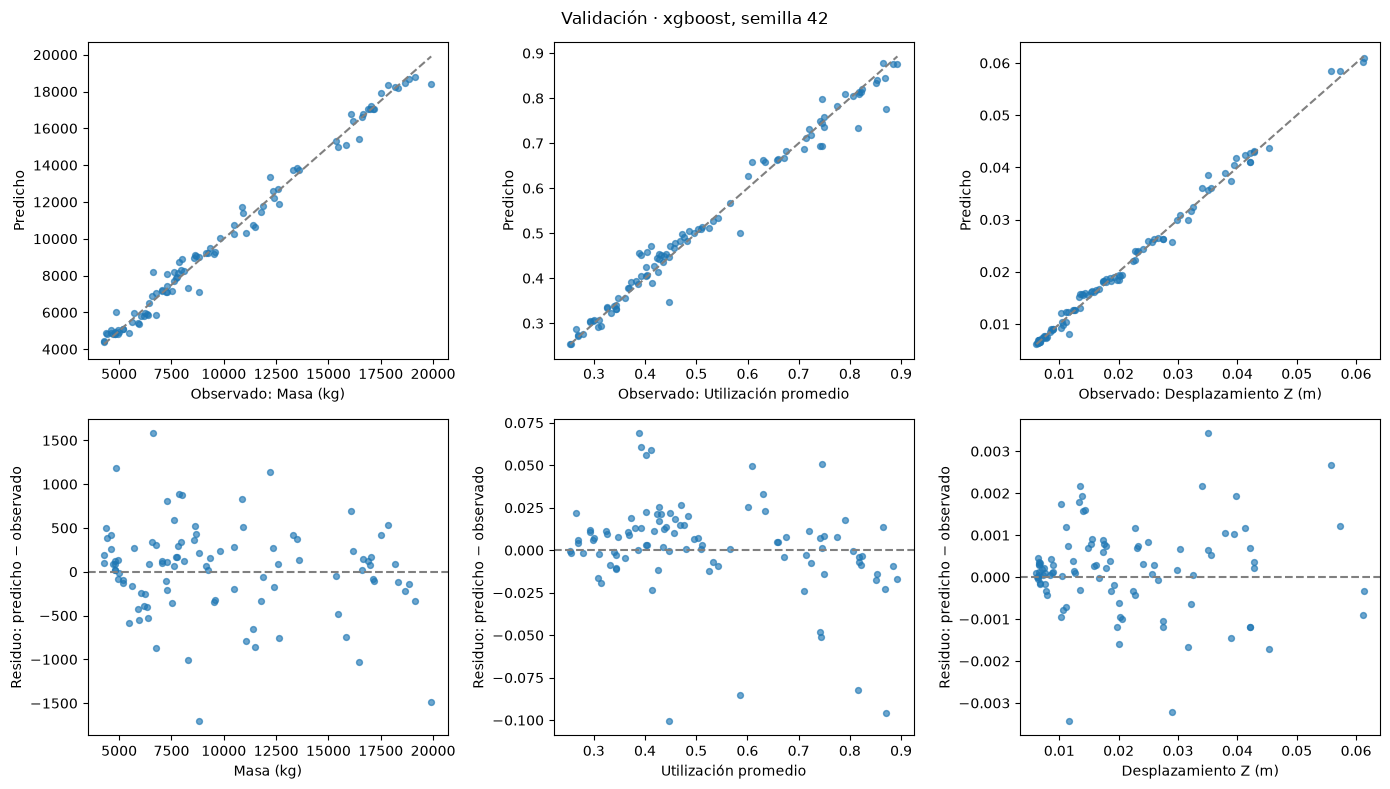

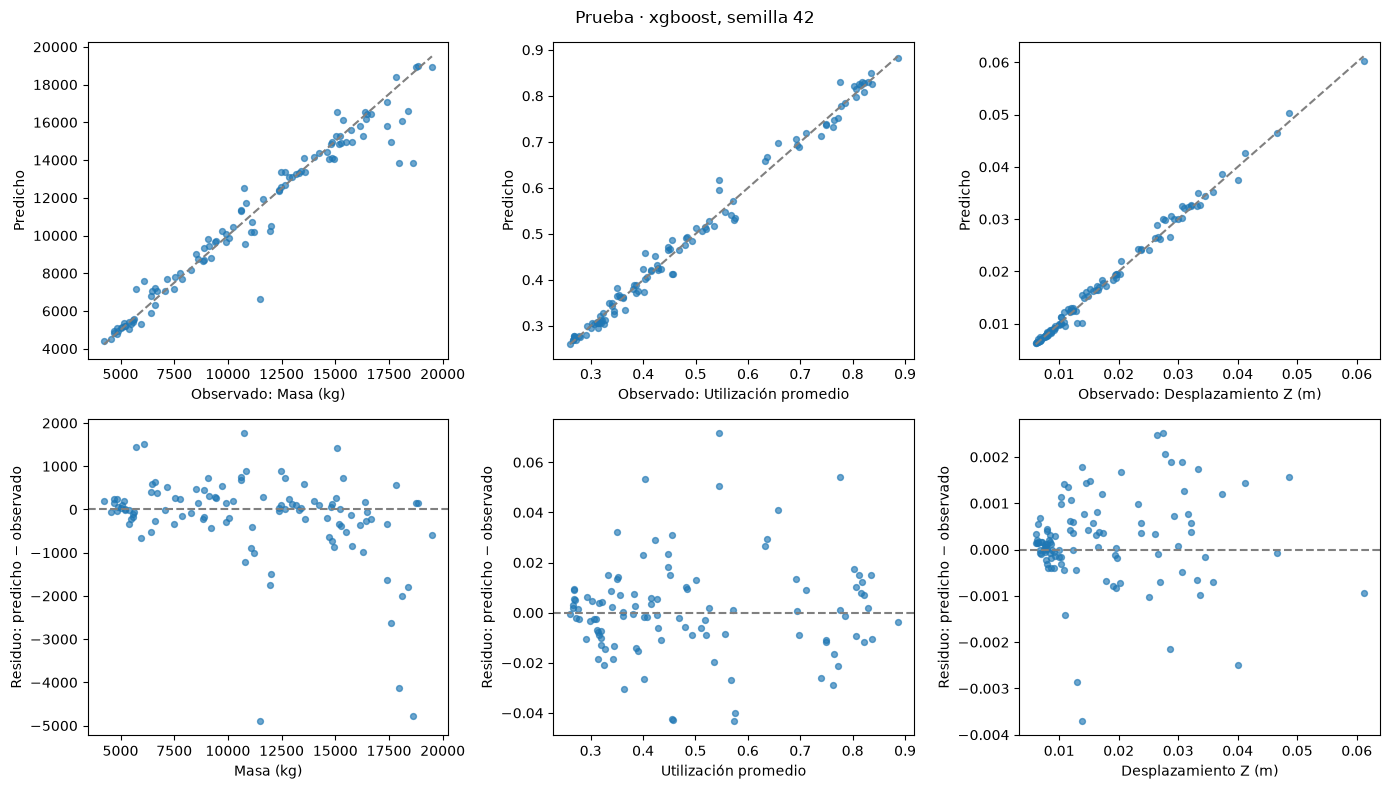

,task,wall_seconds,cpu_seconds,peak_rss_mib,attempts
0,predictor/catboost/42,10.627474,10.343750,714.351562,1
1,predictor/catboost/42/outer_0,722.101250,629.468750,727.160156,1
2,predictor/catboost/42/outer_1,1091.298276,1007.234375,727.828125,1
3,predictor/catboost/42/outer_2,1082.770208,996.656250,730.664062,1
4,predictor/catboost/42/outer_3,1195.947529,1112.906250,732.988281,1
...,...,...,...,...,...
116,predictor/xgboost/42/search,44.197533,30.703125,881.324219,1
117,predictor/xgboost/43,2.095506,1.734375,949.644531,1
118,predictor/xgboost/44,2.028187,1.875000,942.398438,1
119,predictor/xgboost/45,2.054210,1.765625,950.097656,1


,scope,wall_seconds,wall_seconds_scope,campaign_wall_seconds,campaign_wall_seconds_scope,cpu_workers,cpu_seconds,peak_rss_mib,peak_rss_scope,complete
0,predictive_all_recorded_attempts,16543.515836,sum_of_job_durations_not_campaign_elapsed,7087.090207,predictive_coordinator_invocations_only_polici...,12,15069.859375,2069.976562,maximum_single_worker_not_total_simultaneous_m...,True


In [8]:
from truss_research.evaluacion.figuras import prediction_diagnostics

for figure in prediction_diagnostics(
    REPORT_DIR, (context.frozen["selected"][0], CONFIG.representative_seed)
):
    display(figure)
    plt.close(figure)
display(pd.read_csv(REPORT_DIR / "resource_tasks.csv"))
display(pd.read_csv(REPORT_DIR / "research_cost.csv"))